In [1]:
%run photolab.py gamma ../../lectures/L05-filtering/demo/iu-building.jpg --gamma 0.5 -o out/g05.jpg --hist out/g05_hist.png

{"command": "gamma", "gamma": 0.5, "before": {"mean": 134.6, "p1": 3, "median": 123, "p99": 254, "clipped_black_pct": 0.1, "clipped_white_pct": 0.33}, "after": {"mean": 174.3, "p1": 24, "median": 177, "p99": 254, "clipped_black_pct": 0.02, "clipped_white_pct": 0.72}, "out": "out/g05.jpg"}


In [2]:
%run photolab.py wb ../../lectures/L03-color-histograms/demo/ball-lamp.jpg --method grey-world -o out/wb_gw.jpg

{"command": "wb", "method": "grey-world", "gains_bgr": [0.999, 1.028, 0.975], "means_before_bgr": [61.3, 59.6, 62.8], "means_after_bgr": [61.3, 61.2, 61.2], "out": "out/wb_gw.jpg"}


In [3]:
%run photolab.py wb ../../lectures/L03-color-histograms/demo/ball-lamp.jpg --method white-patch -o out/wb_wp.jpg

{"command": "wb", "method": "white-patch", "gains_bgr": [2.318, 2.217, 2.008], "means_before_bgr": [61.3, 59.6, 62.8], "means_after_bgr": [142.1, 132.0, 126.0], "out": "out/wb_wp.jpg"}


In [4]:
%run photolab.py clahe ../../lectures/L05-filtering/demo/iu-building.jpg --clip 2 --tiles 8 -o out/clahe.jpg --compare out/clahe_cmp.jpg

{"command": "clahe", "clip": 2.0, "tiles": 8, "local_contrast": {"исходный": {"shadow_std": 21.1, "shadow_mean": 30.7, "light_mean": 240.7, "light_std": 11.7}, "equalizeHist": {"shadow_std": 14.8, "shadow_mean": 25.5, "light_mean": 230.3, "light_std": 16.0}, "CLAHE": {"shadow_std": 32.3, "shadow_mean": 46.6, "light_mean": 230.5, "light_std": 20.5}}, "out": "out/clahe.jpg"}


In [5]:
%run photolab.py rotate ../../lectures/L05-filtering/demo/iu-building.jpg --deg 30 -o out/rot30.jpg

{"command": "rotate", "deg": 30.0, "size_in": [1920, 1279], "size_out": [2302, 2068], "canvas_empty_pct": 48.4, "out": "out/rot30.jpg"}


In [6]:
%run photolab.py resize ../../lectures/L05-filtering/demo/iu-building.jpg --scale 0.25 --report -o out/small.jpg

{"command": "resize", "scale": 0.25, "method": "area", "size_out": [480, 320], "out": "out/small.jpg", "psnr_vs_lanczos_db": {"naive": 27.9, "blur": 36.0, "area": 37.2}}


In [7]:
%run photolab.py resize ../../lectures/L05-filtering/demo/iu-building.jpg --scale 2 -o out/big.jpg

{"command": "resize", "scale": 2.0, "method": "area", "size_out": [3840, 2558], "out": "out/big.jpg"}


In [8]:
import sys
sys.path.insert(0, "template")
import importlib, photolab
importlib.reload(photolab)
import numpy as np

pts = np.float32([[1290, 1010], [560, 330], [600, 840], [1250, 220]])
print(photolab.order_corners(pts))

[[ 560.  330.]
 [1250.  220.]
 [1290. 1010.]
 [ 600.  840.]]


In [9]:
%run photolab.py rectify ../../lectures/L04-geometry/demo/poster-angle.jpg --corners 1290,1010,560,330,600,840,1250,220 --aspect 0.707 -o out/front.jpg

{"command": "rectify", "corners_ordered": [[560.0, 330.0], [1250.0, 220.0], [1290.0, 1010.0], [600.0, 840.0]], "sides_px": {"top": 698.7, "right": 791.0, "bottom": 710.6, "left": 511.6}, "size_out": [711, 1006], "aspect_out": 0.707, "out": "out/front.jpg"}


In [10]:
%run photolab.py sheet ../../lectures/L05-filtering/demo/iu-building.jpg ../../lectures/L03-color-histograms/demo/ball-day.jpg ../../lectures/L04-geometry/demo/poster-angle.jpg ../../lectures/L04-geometry/demo/road-cam.jpg --cols 3 -o out/sheet.jpg

{"command": "sheet", "n": 4, "cols": 3, "size_out": [992, 556], "out": "out/sheet.jpg"}


In [11]:
%run photolab.py chromakey ../../lectures/L03-color-histograms/demo/ball-lamp.jpg --bg ../../lectures/L04-geometry/demo/road-cam.jpg --lo 140,121,40 --hi 168,230,255 -o out/ck.jpg --mask out/ck_mask.png

{"command": "chromakey", "lo": [140, 121, 40], "hi": [168, 230, 255], "components": 1, "centroid": [189.55742296918768, 558.3688475390156], "bbox": [133, 502, 115, 116], "area": 9996, "raw_components": 1, "holes": 0, "mask_pct": 1.63, "out": "out/ck.jpg"}


In [12]:
!python -m pytest tests -q


...........                                                              [100%]
11 passed in 0.73s


In [13]:
import os, cv2
os.makedirs("out", exist_ok=True)
for f in sorted(os.listdir("data")):
    p = os.path.join("data", f)
    if not os.path.isfile(p):
        continue
    img = cv2.imread(p)
    if img is None:
        print(f, "— не читается")
        continue
    h, w = img.shape[:2]
    kb = os.path.getsize(p) // 1024
    print("%-20s %4d×%-4d  %4d КБ" % (f, w, h, kb))

_poster_aligned.jpg  1531×1339   356 КБ
_poster_small.jpg     384×512     48 КБ
bg.jpg                960×1280    69 КБ
bright.jpg            960×1280   190 КБ
dark.jpg              960×1280    35 КБ
object.jpg           1500×2000   335 КБ
poster.jpg            960×1280   197 КБ
superbright.jpg       960×1280    31 КБ
text.jpg             1500×2000   468 КБ


In [14]:
import os, cv2
LIMIT_PX, LIMIT_KB = 2000, 1500
def shrink(path):
    img = cv2.imread(path)
    h, w = img.shape[:2]
    if max(h, w) > LIMIT_PX:
        s = LIMIT_PX / max(h, w)
        img = cv2.resize(img, (int(w*s), int(h*s)), interpolation=cv2.INTER_AREA)
    cv2.imwrite(path, img, [cv2.IMWRITE_JPEG_QUALITY, 88])
    return img.shape[1], img.shape[0], os.path.getsize(path) // 1024
for f in sorted(os.listdir("data")):
    if f.lower().endswith((".jpg", ".jpeg", ".png")):
        w, h, kb = shrink(os.path.join("data", f))
        print("%-20s → %4d×%-4d  %4d КБ" % (f, w, h, kb))

_poster_aligned.jpg  → 1531×1339   228 КБ
_poster_small.jpg    →  384×512     48 КБ
bg.jpg               →  960×1280    69 КБ
bright.jpg           →  960×1280   190 КБ
dark.jpg             →  960×1280    35 КБ
object.jpg           → 1500×2000   335 КБ
poster.jpg           →  960×1280   197 КБ
superbright.jpg      →  960×1280    31 КБ
text.jpg             → 1500×2000   468 КБ


In [15]:
%run photolab.py gamma data/dark.jpg --gamma 0.5 -o out/dark_g05.jpg --hist out/dark_g05_hist.png

{"command": "gamma", "gamma": 0.5, "before": {"mean": 7.4, "p1": 1, "median": 5, "p99": 33, "clipped_black_pct": 0.18, "clipped_white_pct": 0.0}, "after": {"mean": 39.8, "p1": 16, "median": 37, "p99": 91, "clipped_black_pct": 0.17, "clipped_white_pct": 0.0}, "out": "out/dark_g05.jpg"}


In [16]:
%run photolab.py gamma data/dark.jpg --gamma 2.0 -o out/dark_g20.jpg --hist out/dark_g20_hist.png

{"command": "gamma", "gamma": 2.0, "before": {"mean": 7.4, "p1": 1, "median": 5, "p99": 33, "clipped_black_pct": 0.18, "clipped_white_pct": 0.0}, "after": {"mean": 0.3, "p1": 0, "median": 0, "p99": 4, "clipped_black_pct": 82.94, "clipped_white_pct": 0.0}, "out": "out/dark_g20.jpg"}


In [17]:
%run photolab.py wb data/bright.jpg --method grey-world -o out/bright_gw.jpg --hist out/bright_gw_hist.png

{"command": "wb", "method": "grey-world", "gains_bgr": [1.038, 1.001, 0.964], "means_before_bgr": [178.5, 185.1, 192.1], "means_after_bgr": [184.0, 185.1, 185.2], "out": "out/bright_gw.jpg"}


In [18]:
%run photolab.py wb data/bright.jpg --method white-patch -o out/bright_wp.jpg --hist out/bright_wp_hist.png

{"command": "wb", "method": "white-patch", "gains_bgr": [1.0, 1.0, 1.0], "means_before_bgr": [178.5, 185.1, 192.1], "means_after_bgr": [178.5, 185.1, 192.1], "out": "out/bright_wp.jpg"}


In [19]:
%run photolab.py clahe data/dark.jpg --clip 2 --tiles 8 -o out/dark_clahe.jpg --compare out/dark_cmp.jpg --hist out/dark_clahe_hist.png

{"command": "clahe", "clip": 2.0, "tiles": 8, "local_contrast": {"исходный": {"shadow_std": 0.5, "shadow_mean": 1.6, "light_mean": 15.9, "light_std": 7.9}, "equalizeHist": {"shadow_std": 29.3, "shadow_mean": 76.4, "light_mean": 230.2, "light_std": 14.2}, "CLAHE": {"shadow_std": 1.4, "shadow_mean": 6.6, "light_mean": 38.6, "light_std": 17.4}}, "out": "out/dark_clahe.jpg"}


In [20]:
%run photolab.py rotate data/poster.jpg --deg 30 -o out/poster_rot30.jpg

{"command": "rotate", "deg": 30.0, "size_in": [960, 1280], "size_out": [1471, 1589], "canvas_empty_pct": 47.4, "out": "out/poster_rot30.jpg"}


In [21]:
%run photolab.py resize data/text.jpg --scale 0.25 --report -o out/text_x025.jpg

{"command": "resize", "scale": 0.25, "method": "area", "size_out": [375, 500], "out": "out/text_x025.jpg", "psnr_vs_lanczos_db": {"naive": 33.9, "blur": 39.4, "area": 41.9}}


In [22]:
%run photolab.py resize data/text.jpg --scale 2 -o out/text_x2.jpg

{"command": "resize", "scale": 2.0, "method": "area", "size_out": [3000, 4000], "out": "out/text_x2.jpg"}


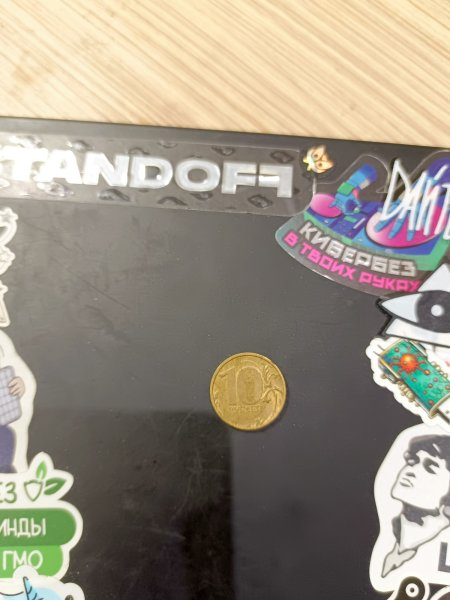

Оригинал: 1500 × 2000 · уменьшено в 0.3×


In [23]:
from IPython.display import Image, display
import cv2

img = cv2.imread("data/object.jpg")
small = cv2.resize(img, None, fx=0.3, fy=0.3, interpolation=cv2.INTER_AREA)
cv2.imwrite("out/_view.jpg", small, [cv2.IMWRITE_JPEG_QUALITY, 85])
display(Image("out/_view.jpg"))
print("Оригинал:", img.shape[1], "×", img.shape[0], "· уменьшено в 0.3×")

In [24]:
%run photolab.py rectify data/poster.jpg --corners 170,340,730,250,890,890,40,980 --aspect 0.707 -o out/poster_front.jpg

{"command": "rectify", "corners_ordered": [[170.0, 340.0], [730.0, 250.0], [890.0, 890.0], [40.0, 980.0]], "sides_px": {"top": 567.2, "right": 659.7, "bottom": 854.8, "left": 653.1}, "size_out": [855, 1209], "aspect_out": 0.707, "out": "out/poster_front.jpg"}


In [25]:
%run photolab.py chromakey data/object.jpg --bg data/bg.jpg --lo 14,90,130 --hi 26,200,255 -o out/object_on_bg.jpg --mask out/object_mask.png

{"command": "chromakey", "lo": [14, 90, 130], "hi": [26, 200, 255], "components": 35, "centroid": [826.1615216169603, 1303.6460089529678], "bbox": [699, 1175, 255, 258], "area": 51603, "raw_components": 218, "holes": 0, "mask_pct": 1.72, "out": "out/object_on_bg.jpg"}


размер: (1339, 1531, 3)


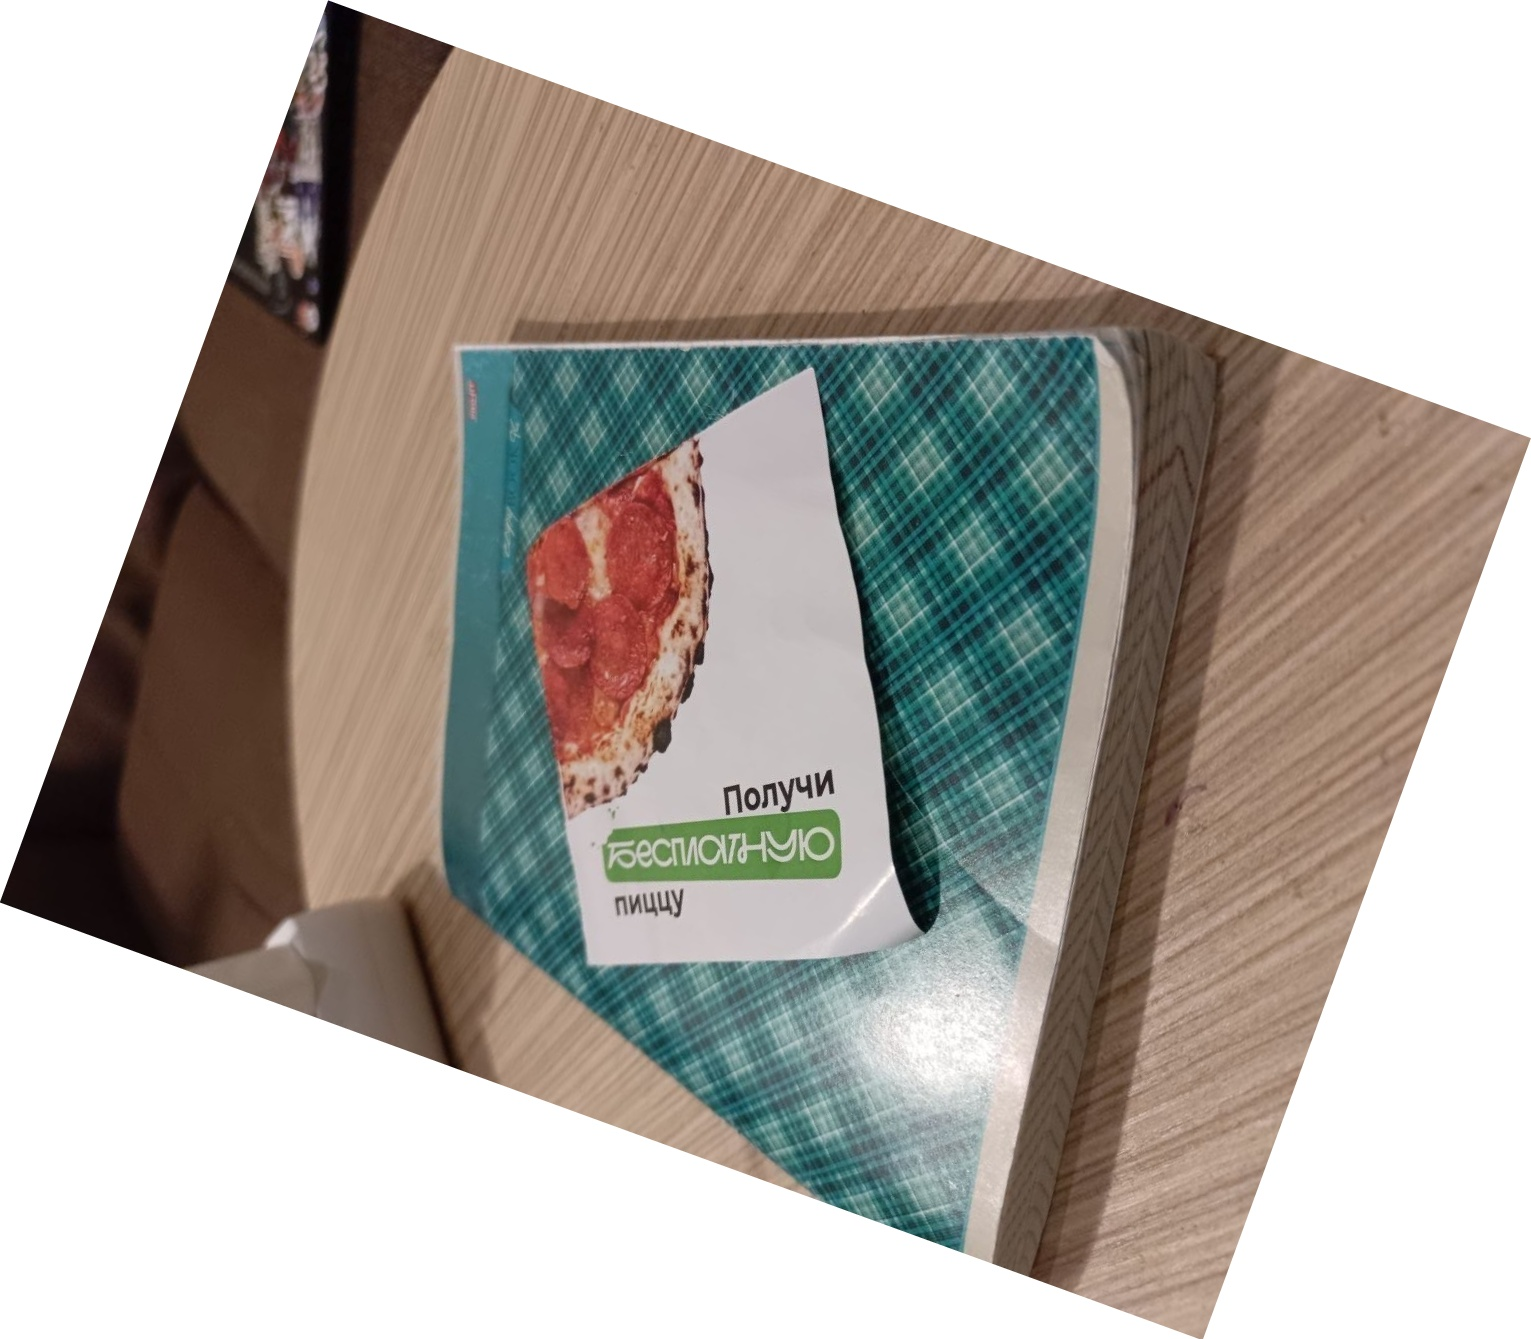

In [26]:
import cv2
import numpy as np
img = cv2.imread("data/poster.jpg")
h, w = img.shape[:2]
M = cv2.getRotationMatrix2D((w/2, h/2), 70, 1.0)
cos, sin = abs(M[0,0]), abs(M[0,1])
nw, nh = int(w*cos + h*sin), int(h*cos + w*sin)
M[0,2] += nw/2 - w/2
M[1,2] += nh/2 - h/2
rotated = cv2.warpAffine(img, M, (nw, nh), borderValue=(255,255,255))
cv2.imwrite("data/_poster_aligned.jpg", rotated)
print("размер:", rotated.shape)
from IPython.display import Image, display
display(Image("data/_poster_aligned.jpg"))

In [27]:
%matplotlib tk
import matplotlib.pyplot as plt
import cv2

img = cv2.imread("data/_poster_aligned.jpg")
small = cv2.resize(img, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)

plt.figure(figsize=(7, 9))
plt.imshow(cv2.cvtColor(small, cv2.COLOR_BGR2RGB))
pts = plt.ginput(4, timeout=0)
plt.close()

orig = [(int(x / 0.5), int(y / 0.5)) for x, y in pts]
print("точки", ",".join(str(v) for p in orig for v in p))

точки 


In [28]:
%run photolab.py rectify data/_poster_aligned.jpg --corners 806,369,913,927,590,961,515,541 --aspect 0.7 -o out/poster_front.jpg


{"command": "rectify", "corners_ordered": [[515.0, 541.0], [806.0, 369.0], [913.0, 927.0], [590.0, 961.0]], "sides_px": {"top": 338.0, "right": 568.2, "bottom": 324.8, "left": 426.6}, "size_out": [338, 483], "aspect_out": 0.7, "out": "out/poster_front.jpg"}


In [29]:
%run photolab.py sheet data/dark.jpg data/bright.jpg data/object.jpg data/poster.jpg data/text.jpg --cols 3 -o out/sheet.jpg

{"command": "sheet", "n": 5, "cols": 3, "size_out": [992, 556], "out": "out/sheet.jpg"}


In [30]:
import os
for f in sorted(os.listdir("out")):
    p = os.path.join("out", f)
    if os.path.isfile(p):
        print("%-35s %6d КБ" % (f, os.path.getsize(p) // 1024))

_view.jpg                               42 КБ
big.jpg                               2015 КБ
bright_gw.jpg                          272 КБ
bright_gw_hist.png                     167 КБ
bright_wp.jpg                          268 КБ
bright_wp_hist.png                     166 КБ
ck.jpg                                 126 КБ
ck_mask.png                              2 КБ
clahe.jpg                              869 КБ
clahe_cmp.jpg                         2309 КБ
dark_clahe.jpg                          80 КБ
dark_clahe_hist.png                    172 КБ
dark_cmp.jpg                           248 КБ
dark_g05.jpg                            82 КБ
dark_g05_hist.png                      101 КБ
dark_g20.jpg                            29 КБ
dark_g20_hist.png                       53 КБ
front.jpg                              172 КБ
g05.jpg                                701 КБ
g05_hist.png                           329 КБ
object_mask.png                          7 КБ
object_on_bg.jpg                  

In [31]:
%run photolab.py chromakey data/object.jpg --bg data/bg.jpg --lo 14,90,130 --hi 26,200,255 -o out/object_on_bg.jpg --mask out/object_mask.png

{"command": "chromakey", "lo": [14, 90, 130], "hi": [26, 200, 255], "components": 35, "centroid": [826.1615216169603, 1303.6460089529678], "bbox": [699, 1175, 255, 258], "area": 51603, "raw_components": 218, "holes": 0, "mask_pct": 1.72, "out": "out/object_on_bg.jpg"}


In [32]:
%run photolab.py rectify data/_poster_aligned.jpg --corners 806,369,913,927,590,961,515,541 --aspect 0.7 -o out/poster_front.jpg

{"command": "rectify", "corners_ordered": [[515.0, 541.0], [806.0, 369.0], [913.0, 927.0], [590.0, 961.0]], "sides_px": {"top": 338.0, "right": 568.2, "bottom": 324.8, "left": 426.6}, "size_out": [338, 483], "aspect_out": 0.7, "out": "out/poster_front.jpg"}


In [33]:
%run photolab.py chromakey ../../lectures/L03-color-histograms/demo/ball-lamp.jpg --bg ../../lectures/L04-geometry/demo/road-cam.jpg --lo 140,121,40 --hi 168,230,255 -o out/ck.jpg --mask out/ck_mask.png

{"command": "chromakey", "lo": [140, 121, 40], "hi": [168, 230, 255], "components": 1, "centroid": [189.55742296918768, 558.3688475390156], "bbox": [133, 502, 115, 116], "area": 9996, "raw_components": 1, "holes": 0, "mask_pct": 1.63, "out": "out/ck.jpg"}
